# 08 — Model Comparison, Selection and Threshold Optimisation
### Telco Customer Churn Prediction

This notebook brings together the training-stage evidence from notebooks 01–07 and makes the remaining modelling decisions, all **without the test set**:
1. which class-imbalance strategy to use;
2. which algorithm to deploy, by a selection rule fixed in advance;
3. which classification threshold turns probabilities into contact decisions;
4. whether these conclusions survive when the preprocessing choices are also made inside the nested loop (robustness check, Section 6).

The comparison uses the **nested out-of-fold predictions** saved by each model notebook. Every training customer's probability comes from a model whose tuning never saw that customer, so the comparison and the threshold are free of *hyperparameter*-selection optimism. The preprocessing configuration was chosen earlier (notebook 00) on the same training folds; Section 6 repeats that choice inside the nested loop to check how much this matters. The decisions are saved to `reports/model_selection.json` and evaluated once in notebook 09.

**Execution order:** run notebooks 01–07 first. This notebook stops with an explicit error if any result file is missing.

## 1. Setup and Loading the Saved Results

In [1]:
import sys
from pathlib import Path

# Make the project's shared src/ package importable, wherever Jupyter was started
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data_preprocessing.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import cross_val_predict

from src.data_preprocessing import FINAL_PREP_CONFIG, RANDOM_STATE, build_pipeline, get_cv, load_raw_data, split_train_test
from src.evaluation import (H_MONTHS, OFFER_MONTHS, REPORT_METRICS, METRIC_LABELS, SUCCESS_RATE, apply_selection_rule,
                            business_outcome, fold_metrics, load_results, pick_threshold, threshold_table)
from src.visualization import plot_fold_scores, plot_reliability, save_figure, set_style

set_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
df = load_raw_data()
X_train, X_test, y_train, y_test = split_train_test(df)
del X_test, y_test   # the test set is not used in this notebook

MODEL_SLUGS = ["01_logistic_regression", "02_decision_tree", "03_random_forest", "04_hist_gradient_boosting",
               "05_xgboost", "06_lightgbm"]
results = {}
for slug in MODEL_SLUGS:
    r = load_results(slug)
    assert np.array_equal(r["y_index"], y_train.index.to_numpy()), f"{slug}: training rows do not match"
    results[r["name"]] = r
imbalance = load_results("07_imbalance_comparison")
assert np.array_equal(imbalance["y_index"], y_train.index.to_numpy())
MODEL_NAMES = list(results)
print("Loaded:", MODEL_NAMES)

Loaded: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'HistGradientBoosting', 'XGBoost', 'LightGBM']


## 2. Class-Imbalance Strategy (from notebook 07)

In [2]:
display(imbalance["paired"].round(4))
display(imbalance["table"][["PR-AUC", "ROC-AUC", "Brier score", "mean predicted probability"]].round(4))

mean PR-AUC difference vs None  \
model                strategy                                              
Logistic Regression  None                                         0.0000   
                     Class weighting                              0.0001   
                     Random oversampling                         -0.0016   
                     SMOTENC                                     -0.0020   
HistGradientBoosting None                                         0.0000   
                     Class weighting                             -0.0007   
                     Random oversampling                         -0.0012   
                     SMOTENC                                      0.0011   

                                          SD of difference  \
model                strategy                                
Logistic Regression  None                           0.0000   
                     Class weighting                0.0012   
                     Random oversampling            0.0025   
                     SMOTENC                        0.0035   
HistGradientBoosting None                           0.0000   
                     Class weighting                0.0110   
                     Random oversampling            0.0068   
                     SMOTENC                        0.0065   

                                          folds better than None  
model                strategy                                     
Logistic Regression  None                                      0  
                     Class weighting                           2  
                     Random oversampling                       1  
                     SMOTENC                                   2  
HistGradientBoosting None                                      0  
                     Class weighting                           1  
                     Random oversampling                       1  
                     SMOTENC                                   2

PR-AUC  ROC-AUC  Brier score  \
model                strategy                                            
Logistic Regression  None                 0.6661   0.8461       0.1362   
                     Class weighting      0.6662   0.8465       0.1649   
                     Random oversampling  0.6645   0.8444       0.1650   
                     SMOTENC              0.6641   0.8456       0.1642   
HistGradientBoosting None                 0.6567   0.8438       0.1365   
                     Class weighting      0.6560   0.8433       0.1647   
                     Random oversampling  0.6555   0.8427       0.1638   
                     SMOTENC              0.6578   0.8421       0.1634   

                                          mean predicted probability  
model                strategy                                         
Logistic Regression  None                                     0.2674  
                     Class weighting                          0.4153  
                     Random oversampling                      0.4181  
                     SMOTENC                                  0.4125  
HistGradientBoosting None                                     0.2666  
                     Class weighting                          0.4098  
                     Random oversampling                      0.4052  
                     SMOTENC                                  0.4013

**Decision carried forward from notebook 07:**
- No weighting or resampling strategy changes PR-AUC by more than 0.002 for either model, and all of them worsen calibration.
- The unweighted results saved by notebooks 01–06 are therefore the candidates compared below.

## 3. Consolidated Comparison

Two **Dummy** classifiers give the no-skill reference: *most frequent* always predicts "no churn", and *stratified* guesses at the training churn rate. They have no hyperparameters, so ordinary cross-validated predictions are already unbiased for them.

In [3]:
dummy_oof = {}
for label, strategy in [("Dummy (most frequent)", "most_frequent"), ("Dummy (stratified)", "stratified")]:
    dummy = build_pipeline(DummyClassifier(strategy=strategy, random_state=RANDOM_STATE), **FINAL_PREP_CONFIG)
    dummy_oof[label] = cross_val_predict(dummy, X_train, y_train, cv=get_cv(), method="predict_proba")[:, 1]

INTERPRETABILITY = {"Logistic Regression": "High (coefficients, odds ratios)", "Decision Tree": "High at small depth (rules)",
                    "Random Forest": "Low (300 trees; post-hoc tools)", "HistGradientBoosting": "Low (200 trees; post-hoc tools)",
                    "XGBoost": "Low (300 trees; post-hoc tools)", "LightGBM": "Low (200 trees; post-hoc tools)"}
rows = []
for label, proba in dummy_oof.items():
    m = fold_metrics(y_train, proba)
    rows.append({"model": label, "PR-AUC mean": m["pr_auc"], "PR-AUC std": np.nan, "ROC-AUC mean": m["roc_auc"],
                 "ROC-AUC std": np.nan, "Brier score": m["brier"], "Accuracy @0.5": m["accuracy"],
                 "Precision @0.5": m["precision"], "Recall @0.5": m["recall"], "F1 @0.5": m["f1"],
                 "nested CV time (s)": np.nan, "final hyperparameters": "-", "interpretability": "-"})
for name, r in results.items():
    f = r["folds"]
    rows.append({"model": name, "PR-AUC mean": f["pr_auc"].mean(), "PR-AUC std": f["pr_auc"].std(ddof=0),
                 "ROC-AUC mean": f["roc_auc"].mean(), "ROC-AUC std": f["roc_auc"].std(ddof=0),
                 "Brier score": f["brier"].mean(), "Accuracy @0.5": f["accuracy"].mean(),
                 "Precision @0.5": f["precision"].mean(), "Recall @0.5": f["recall"].mean(), "F1 @0.5": f["f1"].mean(),
                 "nested CV time (s)": r["seconds"], "final hyperparameters": str(r["final_params"]),
                 "interpretability": INTERPRETABILITY[name]})
comparison = pd.DataFrame(rows).set_index("model")
display(comparison.drop(columns=["final hyperparameters"]).round(4))
display(comparison[["final hyperparameters"]])

,PR-AUC mean,PR-AUC std,ROC-AUC mean,ROC-AUC std,Brier score,Accuracy @0.5,Precision @0.5,Recall @0.5,F1 @0.5,nested CV time (s),interpretability
model,,,,,,,,,,,
Dummy (most frequent),0.2670,NaN,0.5000,NaN,0.2670,0.7330,0.0000,0.0000,0.0000,NaN,-
Dummy (stratified),0.2673,NaN,0.5009,NaN,0.3945,0.6055,0.2682,0.2764,0.2722,NaN,-
Logistic Regression,0.6661,0.0273,0.8461,0.0148,0.1362,0.7987,0.6643,0.5090,0.5732,4.0013,"High (coefficients, odds ratios)"
Decision Tree,0.6226,0.0114,0.8295,0.0089,0.1420,0.7906,0.6389,0.5080,0.5639,8.2560,High at small depth (rules)
Random Forest,0.6633,0.0235,0.8447,0.0137,0.1367,0.7941,0.6593,0.4776,0.5524,43.5568,Low (300 trees; post-hoc tools)
HistGradientBoosting,0.6567,0.0151,0.8438,0.0116,0.1365,0.7944,0.6450,0.5185,0.5732,15.6930,Low (200 trees; post-hoc tools)
XGBoost,0.6655,0.0214,0.8465,0.0133,0.1364,0.7989,0.6636,0.5080,0.5731,87.3298,Low (300 trees; post-hoc tools)
LightGBM,0.6649,0.0183,0.8464,0.0126,0.1363,0.7956,0.6553,0.4985,0.5648,10.9186,Low (200 trees; post-hoc tools)


,final hyperparameters
model,
Dummy (most frequent),-
Dummy (stratified),-
Logistic Regression,"{'C': 1, 'l1_ratio': 0.0}"
Decision Tree,"{'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 50}"
Random Forest,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 15}"
HistGradientBoosting,"{'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_leaf_nodes': 4, 'min_samples_leaf': 50}"
XGBoost,"{'learning_rate': 0.01, 'max_depth': 4, 'min_child_weight': 5, 'reg_lambda': 1.0}"
LightGBM,"{'learning_rate': 0.03, 'min_child_samples': 50, 'num_leaves': 4, 'reg_lambda': 1.0}"


,Logistic Regression,Decision Tree,Random Forest,HistGradientBoosting,XGBoost,LightGBM
outer fold,,,,,,
1,0.6454,0.6037,0.6536,0.6390,0.6423,0.6536
2,0.7191,0.6360,0.7100,0.6847,0.7062,0.7010
3,0.6610,0.6205,0.6551,0.6558,0.6585,0.6574
4,0.6597,0.6199,0.6515,0.6507,0.6597,0.6521
5,0.6454,0.6329,0.6464,0.6535,0.6609,0.6603


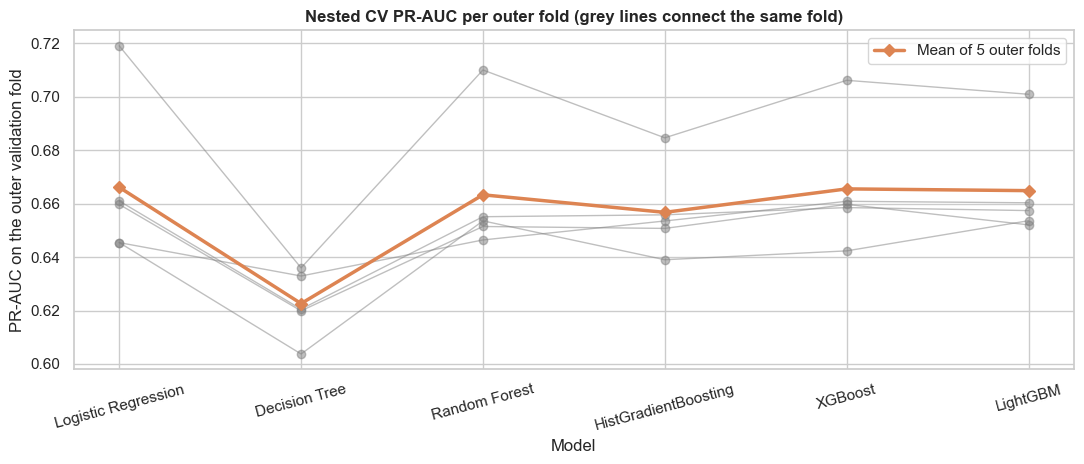

In [4]:
fold_pr = pd.DataFrame({name: r["folds"]["pr_auc"] for name, r in results.items()})
display(fold_pr.round(4).rename_axis("outer fold"))

fig, ax = plt.subplots(figsize=(11, 4.8))
plot_fold_scores(ax, fold_pr, "Nested CV PR-AUC per outer fold (grey lines connect the same fold)")
plt.tight_layout()
save_figure(fig, "08_fold_scores")
plt.show()

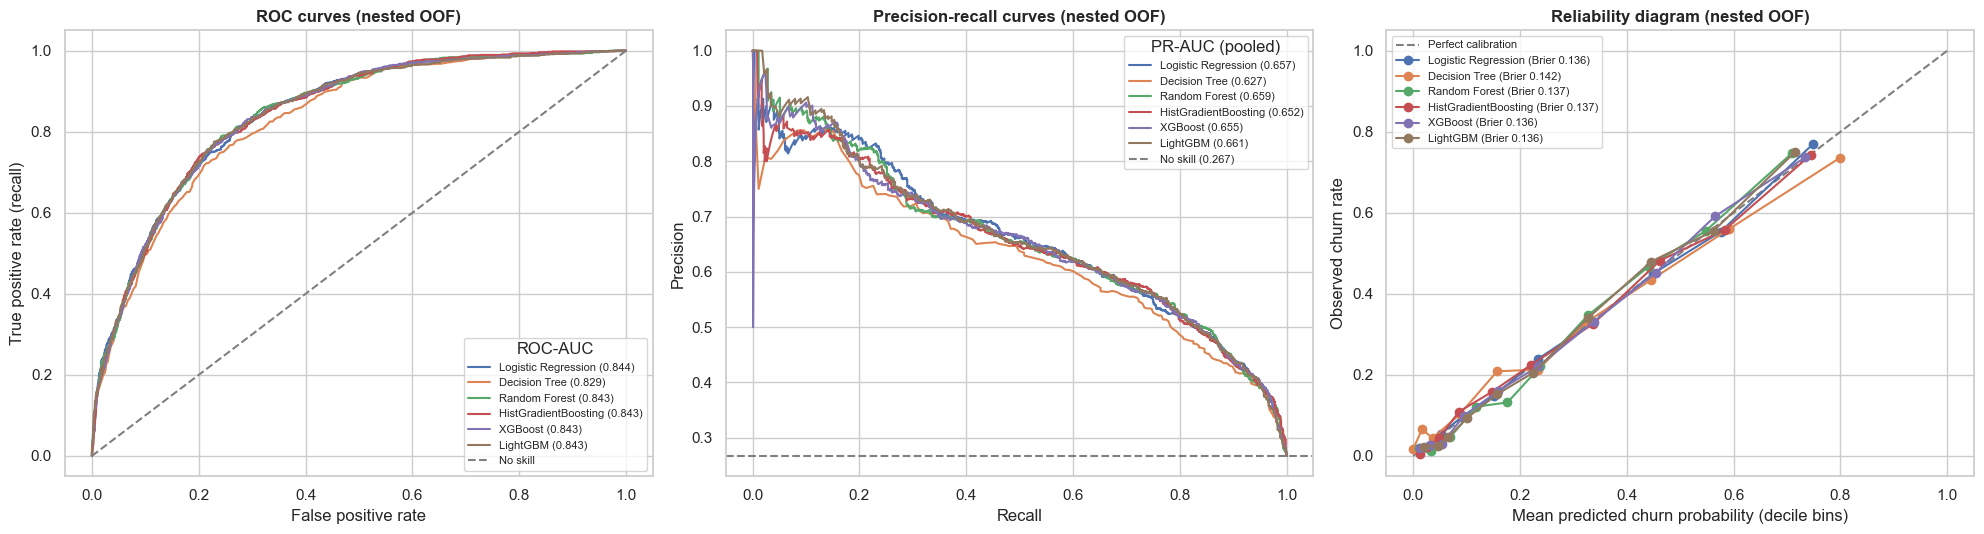

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_train, r["oof"])
    axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_train, r['oof']):.3f})")
    prec, rec, _ = precision_recall_curve(y_train, r["oof"])
    axes[1].plot(rec, prec, label=f"{name} ({average_precision_score(y_train, r['oof']):.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="No skill")
axes[0].set_title("ROC curves (nested OOF)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].legend(fontsize=8, title="ROC-AUC")
axes[1].axhline(y_train.mean(), linestyle="--", color="gray", label=f"No skill ({y_train.mean():.3f})")
axes[1].set_title("Precision-recall curves (nested OOF)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8, title="PR-AUC (pooled)")
plot_reliability(axes[2], y_train, {n: r["oof"] for n, r in results.items()}, "Reliability diagram (nested OOF)")
plt.tight_layout()
save_figure(fig, "08_roc_pr_calibration")
plt.show()

**Interpretation**

- **Baselines.** The Dummy (most frequent) classifier reaches 73.3% accuracy with zero recall, and its PR-AUC (0.267) equals the churn rate. Every real model is far above that.
- **Five of the six tuned models are statistically indistinguishable:**

  | Model | Nested PR-AUC |
  |---|---|
  | Logistic Regression | **0.666 ± 0.027** |
  | XGBoost | 0.666 ± 0.021 |
  | LightGBM | 0.665 ± 0.018 |
  | Random Forest | 0.663 ± 0.024 |
  | HistGradientBoosting | 0.657 ± 0.015 |

  Their ROC-AUCs lie between 0.844 and 0.847, and their Brier scores between 0.136 and 0.137. The ROC and precision-recall curves overlap almost everywhere, and every model is well calibrated.
- **The Decision Tree is the only clearly weaker model** (0.623).
- **Fold difficulty matters more than model choice.** Fold 2 is the easiest fold for every model (0.685–0.719 for the five leading models, 0.636 for the tree), and the grey lines cross: no model is best in every fold.
- **Threshold-dependent metrics at 0.5** are similar for all tuned models (accuracy 0.79–0.80, recall 0.48–0.52). They are not a basis for selection, because the threshold has not been optimised.
- **Computational cost** differs a lot: the nested CV took about 4 s for Logistic Regression versus 37 s for Random Forest and 81 s for XGBoost.

## 4. Model Selection

**Rule** (fixed in the earlier phase of the project, before any test-set evaluation, and unchanged here):

> Candidates are ordered by interpretability: Logistic Regression → Decision Tree → Random Forest → HistGradientBoosting → XGBoost → LightGBM. The model with the highest mean nested PR-AUC is the reference. The **most interpretable** model is selected unless the reference beats it by **more than 0.02 PR-AUC** (about one fold standard deviation) **and** in **at least 4 of the 5 outer folds**.

XGBoost and LightGBM are new candidates. They are placed after HistGradientBoosting because they are equally opaque and add an external dependency. The margin and fold count are code constants of `apply_selection_rule` in `src/evaluation.py`.

In [6]:
INTERPRETABILITY_ORDER = sorted(results, key=lambda n: results[n]["interpretability_rank"])
FINAL_MODEL_NAME, reference_model, selection_table = apply_selection_rule(fold_pr[INTERPRETABILITY_ORDER],
                                                                          INTERPRETABILITY_ORDER)
display(selection_table.round(4))
print(f"Highest mean nested PR-AUC: {reference_model}")
print(f"Selected model: {FINAL_MODEL_NAME}")

,mean nested PR-AUC,gap to best (Logistic Regression),folds where best is higher,clearly worse than best?
model,,,,
Logistic Regression,0.6661,0.0000,0,False
Decision Tree,0.6226,0.0435,5,True
Random Forest,0.6633,0.0028,3,False
HistGradientBoosting,0.6567,0.0094,4,False
XGBoost,0.6655,0.0006,3,False
LightGBM,0.6649,0.0013,3,False


Highest mean nested PR-AUC: Logistic Regression
Selected model: Logistic Regression


**Result.**
- Logistic Regression has the highest mean nested PR-AUC (0.6661), so it is both the reference and the most interpretable candidate. **It is selected without trading accuracy for interpretability.**
- XGBoost (−0.0006), LightGBM (−0.0013), Random Forest (−0.0028) and HistGradientBoosting (−0.0094) are not clearly worse by the rule. HistGradientBoosting is below Logistic Regression in 4 folds, but its mean gap is less than half the 0.02 margin; the others trail by less than 0.003.
- The Decision Tree is clearly worse (−0.044, below in all 5 folds).
- Had a boosting model come out marginally ahead, the rule would still have chosen Logistic Regression unless the gain exceeded 0.02 in at least four folds. **No result came close to that margin.**

**Why Logistic Regression is the defensible final model**
1. Equal ranking quality to the best ensembles.
2. The smallest training–validation gap (0.002).
3. Readable coefficients and odds ratios for the CS team.
4. Well-calibrated probabilities.
5. A trivial deployment footprint with no extra dependencies.

### Permutation importance across models

The importances below were computed inside each model's nested CV (outer validation folds), so they can be compared directly.

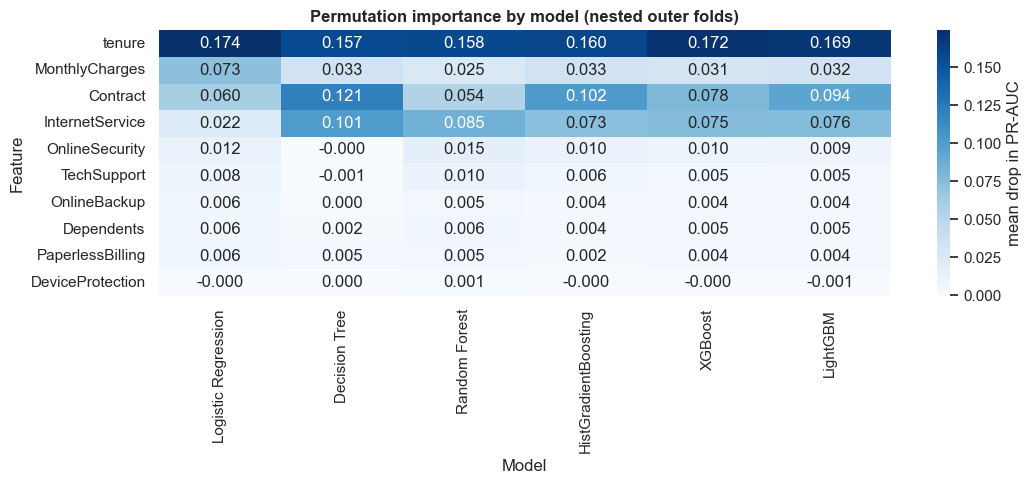

In [7]:
importance_matrix = pd.DataFrame({name: r["importance"].groupby("feature")["importance"].mean()
                                  for name, r in results.items()})
importance_matrix = importance_matrix.loc[importance_matrix[FINAL_MODEL_NAME].sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(importance_matrix, annot=True, fmt=".3f", cmap="Blues", ax=ax, cbar_kws={"label": "mean drop in PR-AUC"})
ax.set_title("Permutation importance by model (nested outer folds)")
ax.set_xlabel("Model")
ax.set_ylabel("Feature")
plt.tight_layout()
save_figure(fig, "08_importance_heatmap")
plt.show()

**Interpretation.**
- **All six models agree that `tenure` is by far the most important feature** (0.157–0.174), and that `DeviceProtection` contributes nothing.
- They differ in how they use the overlapping service information:
  - Logistic Regression relies on `MonthlyCharges` (0.073) as a continuous risk gradient;
  - the tree-based models rely on `Contract` and `InternetService` as group splits.
- Each model reaches similar predictions through different but equivalent descriptions of the same customer types. That is consistent with their almost identical accuracy.

## 5. Threshold Optimisation

The selected model outputs a churn probability; the **threshold** turns it into an action (contact if probability ≥ *t*). Changing *t* does not change the ranking of customers, so **ROC-AUC and PR-AUC are unaffected**. It does move customers between predicted classes, which changes accuracy, precision, recall, F1 and the confusion matrix. Lowering *t* catches more churners (fewer false negatives) at the cost of more unnecessary contacts (more false positives).

The threshold is chosen from the selected model's **nested OOF probabilities**, on the training set only.

### 5.1 Business cost model (illustrative assumptions)

No financial data are available. The cost model uses **hypothetical values** agreed by the project team; only `MonthlyCharges` comes from the data.

| Symbol | Meaning | Base value | Source |
|---|---|---|---|
| `H` | Months of revenue lost when a customer churns | 12 | **Assumption** |
| `s` | Probability that a contacted churner is retained by the offer | 30% | **Assumption** |
| `c` | Offer cost per contacted customer, in months of that customer's charges | 1 | **Assumption** |
| $m_i$ | Customer's monthly charge | per customer | Dataset |

| Outcome | Expected cost for customer *i* |
|---|---|
| TP — contacted churner | $c\,m_i + (1-s)\,H\,m_i$ |
| FP — contacted non-churner | $c\,m_i$ |
| FN — missed churner | $H\,m_i$ |
| TN | 0 |

> **Revenue is not profit.** $H \times m_i$ is gross **revenue at risk**. Profit would subtract the unknown cost of serving the customer. The offer cost is real spending (or forgone revenue). The amounts are in the dataset's undocumented currency units and are useful for **comparing strategies**, not as forecasts of savings.

**Theoretical check.** If probabilities are well calibrated, contacting customer *i* pays off when $p_i \cdot s \cdot H \cdot m_i > c \cdot m_i$, i.e. $p_i > c/(sH) = 1/3.6 \approx 0.28$ under the base assumptions.

In [8]:
monthly_train = X_train["MonthlyCharges"].to_numpy()
p_final = results[FINAL_MODEL_NAME]["oof"]
final_tbl = threshold_table(y_train, p_final, monthly_train)
do_nothing_cost = business_outcome(y_train, np.zeros(len(y_train)), monthly_train)["total expected cost"]
contact_all_cost = business_outcome(y_train, np.ones(len(y_train)), monthly_train)["total expected cost"]
break_even = OFFER_MONTHS / (SUCCESS_RATE * H_MONTHS)

criteria_thresholds = {
    "Default 0.5": 0.50,
    "Maximum F1": pick_threshold(final_tbl, "f1"),
    "Max recall with precision >= 0.60": pick_threshold(final_tbl, "recall", mask=final_tbl["precision"] >= 0.60),
    "Max precision with recall >= 0.80": pick_threshold(final_tbl, "precision", mask=final_tbl["recall"] >= 0.80),
    "Minimum expected cost (business)": pick_threshold(final_tbl, "total expected cost", largest=False),
    f"Theoretical break-even c/(sH) = {break_even:.3f}": float(np.round(break_even, 2)),
}
criteria_table = pd.DataFrame({name: final_tbl.loc[t, ["accuracy", "precision", "recall", "f1", "TP", "FP", "FN", "TN",
                                                        "customers contacted", "total expected cost"]]
                               for name, t in criteria_thresholds.items()}).T
criteria_table.insert(0, "threshold", list(criteria_thresholds.values()))
criteria_table["saving vs do nothing (%)"] = 100 * (1 - criteria_table["total expected cost"].astype(float) / do_nothing_cost)
print(f"Training reference costs: do nothing = {do_nothing_cost:,.0f} | contact everyone = {contact_all_cost:,.0f}")
display(criteria_table.round(3))

FINAL_THRESHOLD = float(criteria_thresholds["Minimum expected cost (business)"])
print(f"Operating threshold (minimum expected cost on nested OOF predictions): {FINAL_THRESHOLD:.2f}")

Training reference costs: do nothing = 939,118 | contact everyone = 912,321


,threshold,accuracy,precision,recall,f1,TP,FP,FN,TN,customers contacted,total expected cost,saving vs do nothing (%)
Default 0.5,0.50,0.799,0.659,0.509,0.574,536.0,277.0,517.0,2614.0,813.0,850144.25,9.474
Maximum F1,0.33,0.773,0.555,0.742,0.635,781.0,625.0,272.0,2266.0,1406.0,829030.59,11.722
Max recall with precision >= 0.60,0.41,0.793,0.607,0.636,0.622,670.0,433.0,383.0,2458.0,1103.0,834294.75,11.162
Max precision with recall >= 0.80,0.27,0.748,0.519,0.806,0.631,849.0,788.0,204.0,2103.0,1637.0,827495.10,11.886
Minimum expected cost (business),0.27,0.748,0.519,0.806,0.631,849.0,788.0,204.0,2103.0,1637.0,827495.10,11.886
Theoretical break-even c/(sH) = 0.278,0.28,0.752,0.524,0.793,0.631,835.0,759.0,218.0,2132.0,1594.0,828012.55,11.831


Operating threshold (minimum expected cost on nested OOF predictions): 0.27


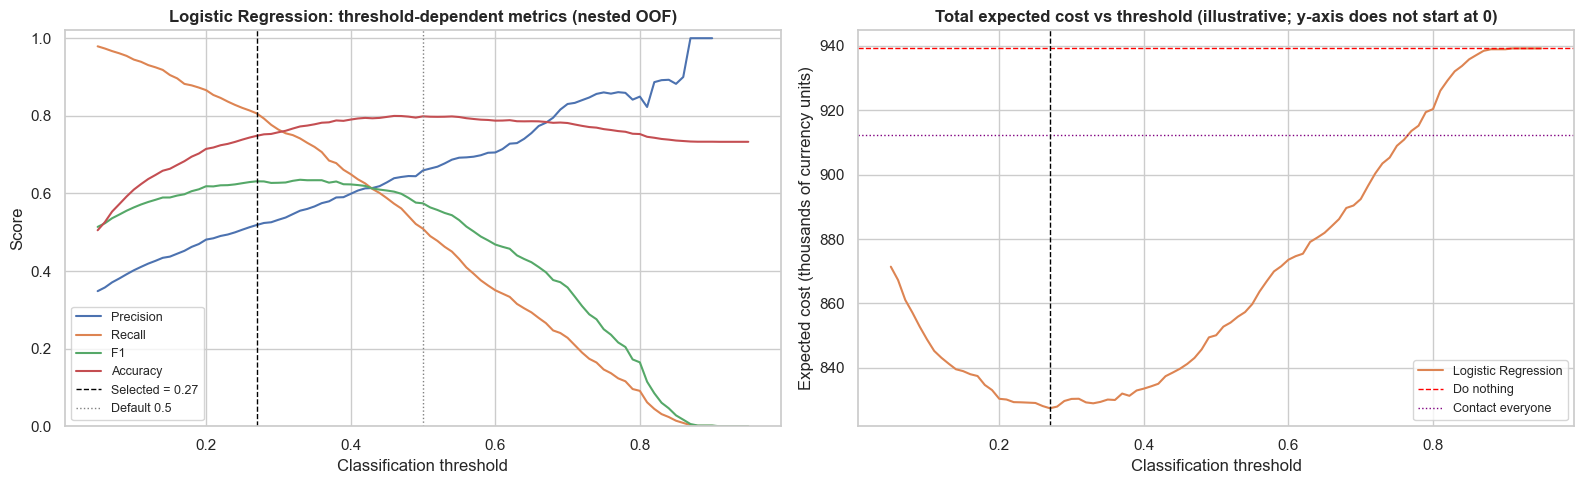

,precision,recall,f1,accuracy,TP,FP,FN,TN,total expected cost
threshold,,,,,,,,,
0.20,0.481,0.866,0.619,0.715,912,984,141,1907,830434.76
0.27,0.519,0.806,0.631,0.748,849,788,204,2103,827495.10
0.30,0.532,0.764,0.627,0.758,805,708,248,2183,830395.98
0.40,0.599,0.650,0.623,0.790,684,458,369,2433,833586.02
0.50,0.659,0.509,0.574,0.799,536,277,517,2614,850144.25
0.60,0.706,0.350,0.468,0.788,369,154,684,2737,873578.52


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for metric, label in [("precision", "Precision"), ("recall", "Recall"), ("f1", "F1"), ("accuracy", "Accuracy")]:
    axes[0].plot(final_tbl.index, final_tbl[metric], label=label)
axes[0].axvline(FINAL_THRESHOLD, color="black", linestyle="--", linewidth=1, label=f"Selected = {FINAL_THRESHOLD:.2f}")
axes[0].axvline(0.5, color="gray", linestyle=":", linewidth=1, label="Default 0.5")
axes[0].set_title(f"{FINAL_MODEL_NAME}: threshold-dependent metrics (nested OOF)")
axes[0].set_xlabel("Classification threshold")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.02)
axes[0].legend(fontsize=9)
axes[1].plot(final_tbl.index, final_tbl["total expected cost"] / 1e3, color="#DD8452", label=FINAL_MODEL_NAME)
axes[1].axhline(do_nothing_cost / 1e3, color="red", linestyle="--", linewidth=1, label="Do nothing")
axes[1].axhline(contact_all_cost / 1e3, color="purple", linestyle=":", linewidth=1, label="Contact everyone")
axes[1].axvline(FINAL_THRESHOLD, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Total expected cost vs threshold (illustrative; y-axis does not start at 0)")
axes[1].set_xlabel("Classification threshold")
axes[1].set_ylabel("Expected cost (thousands of currency units)")
axes[1].legend(fontsize=9)
plt.tight_layout()
save_figure(fig, "08_threshold_analysis")
plt.show()
display(final_tbl.loc[[0.2, 0.27, 0.3, 0.4, 0.5, 0.6], ["precision", "recall", "f1", "accuracy", "TP", "FP", "FN", "TN",
                                                       "total expected cost"]].round(3))

**Interpretation**

- **The threshold changes every threshold-dependent metric, but not the ranking.** For the same probabilities (pooled OOF PR-AUC 0.658, ROC-AUC 0.844 at any threshold):
  - **0.5:** recall 0.509, precision 0.659;
  - **0.27:** recall 0.806, precision 0.519;
  - **0.2:** recall 0.866, precision 0.481.
  - Accuracy peaks around 0.45–0.5 (about 0.80) because that threshold flags few customers. Maximising accuracy would work against the goal of catching churners.

- **The criteria lead to different thresholds:**

  | Criterion | Threshold | Recall | Precision | Saving vs do nothing |
  |---|---|---|---|---|
  | Default | 0.50 | 0.509 | 0.659 | 9.5% |
  | Maximum F1 | 0.33 | 0.742 | 0.555 | 11.7% |
  | Precision ≥ 0.60 | 0.41 | 0.636 | 0.607 | 11.2% |
  | Recall ≥ 0.80 | 0.27 | 0.806 | 0.519 | 11.9% |
  | **Minimum expected cost** | **0.27** | **0.806** | **0.519** | **11.9%** |

- **The business criterion is chosen** because it directly expresses the project objective, balancing missed churners against wasted offers. It also coincides with the original target "recall ≥ 80%".
- **Theory confirms the result.** For calibrated probabilities the break-even is $c/(sH) = 0.278$. The empirical optimum is **0.27**, and the theoretical threshold gives practically the same cost (828,013 vs 827,495). This agreement is only possible because the unweighted model is well calibrated.
- **The cost curve is flat around the optimum** (830,435 at 0.20; 827,495 at 0.27; 830,396 at 0.30), so the choice is not fragile.
- **At t = 0.27 (nested OOF):**
  - 849 of 1,053 churners caught;
  - 788 non-churners contacted unnecessarily;
  - 204 churners missed;
  - 1,637 of 3,944 customers (42%) contacted.

### 5.2 Sensitivity of the threshold to the cost assumptions

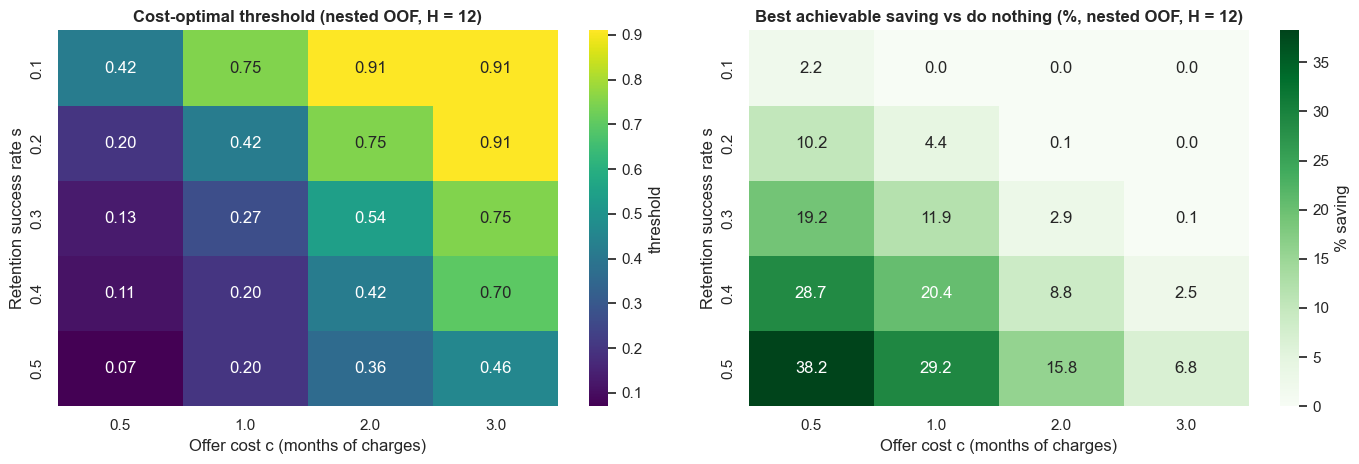

,break-even c/(sH),cost-optimal threshold,best saving vs do nothing (%)
horizon H (months),,,
6,0.556,0.54,2.902
12,0.278,0.27,11.886
24,0.139,0.13,19.249


In [10]:
success_grid, offer_grid, horizon_grid = [0.10, 0.20, 0.30, 0.40, 0.50], [0.5, 1.0, 2.0, 3.0], [6, 12, 24]


def optimal_threshold(horizon=H_MONTHS, success=SUCCESS_RATE, offer_months=OFFER_MONTHS):
    kw = dict(horizon=horizon, success=success, offer_months=offer_months)
    tbl = threshold_table(y_train, p_final, monthly_train, **kw)
    base = business_outcome(y_train, np.zeros(len(y_train)), monthly_train, **kw)["total expected cost"]
    return tbl["total expected cost"].idxmin(), 100 * (1 - tbl["total expected cost"].min() / base)


opt_thr = pd.DataFrame(index=success_grid, columns=offer_grid, dtype=float)
opt_saving = pd.DataFrame(index=success_grid, columns=offer_grid, dtype=float)
for s_val in success_grid:
    for c_val in offer_grid:
        opt_thr.loc[s_val, c_val], opt_saving.loc[s_val, c_val] = optimal_threshold(success=s_val, offer_months=c_val)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.heatmap(opt_thr, annot=True, fmt=".2f", cmap="viridis", ax=axes[0], cbar_kws={"label": "threshold"})
axes[0].set_title("Cost-optimal threshold (nested OOF, H = 12)")
axes[0].set_xlabel("Offer cost c (months of charges)")
axes[0].set_ylabel("Retention success rate s")
sns.heatmap(opt_saving, annot=True, fmt=".1f", cmap="Greens", ax=axes[1], cbar_kws={"label": "% saving"})
axes[1].set_title("Best achievable saving vs do nothing (%, nested OOF, H = 12)")
axes[1].set_xlabel("Offer cost c (months of charges)")
axes[1].set_ylabel("Retention success rate s")
plt.tight_layout()
save_figure(fig, "08_threshold_sensitivity")
plt.show()
display(pd.DataFrame([{"horizon H (months)": h, "break-even c/(sH)": OFFER_MONTHS / (SUCCESS_RATE * h),
                       "cost-optimal threshold": optimal_threshold(horizon=h)[0],
                       "best saving vs do nothing (%)": optimal_threshold(horizon=h)[1]} for h in horizon_grid])
        .set_index("horizon H (months)").round(3))

**Interpretation.**
- **The optimal threshold follows the rule $c/(sH)$.** It falls when offers are cheap and effective (s = 0.5, c = 0.5: 0.07 vs theory 0.083) and rises when they are expensive (s = 0.3, c = 2: 0.54 vs 0.556).
- **The achievable saving ranges widely:** 19–38% with cheap offers (c = 0.5) and s ≥ 0.3, but about **0%** when c ≥ 2 and s ≤ 0.2. In that case the best policy contacts almost no one. **No targeting can rescue an offer that costs more than the revenue it is expected to save.**
- **The horizon matters as much as the offer terms:**

  | H | Break-even | Best saving |
  |---|---|---|
  | 6 months | 0.556 | 2.9% |
  | 12 months | 0.278 | 11.9% |
  | 24 months | 0.139 | 19.2% |

- The threshold must therefore be **re-derived whenever the business assumptions change**. The model itself does not need retraining, because its probabilities are calibrated.

### 5.3 Reassessing the success criteria

In [11]:
prec_curve, rec_curve, _ = precision_recall_curve(y_train, p_final)
folds_final = results[FINAL_MODEL_NAME]["folds"]
criteria = pd.DataFrame([
    {"criterion": "Recall >= 80% AND Precision >= 60% (original, jointly)",
     "evidence (nested OOF)": f"precision at recall>=0.80 is {prec_curve[:-1][rec_curve[:-1] >= 0.80].max():.3f}; "
                              f"best recall with precision>=0.60 is {rec_curve[:-1][prec_curve[:-1] >= 0.60].max():.3f}",
     "met?": bool(prec_curve[:-1][rec_curve[:-1] >= 0.80].max() >= 0.60)},
    {"criterion": "F1 >= 65% (original)", "evidence (nested OOF)": f"maximum F1 over thresholds = {final_tbl['f1'].max():.3f}",
     "met?": bool(final_tbl["f1"].max() >= 0.65)},
    {"criterion": "ROC-AUC >= 80% (original, kept)", "evidence (nested OOF)": f"nested ROC-AUC = {folds_final['roc_auc'].mean():.3f}",
     "met?": bool(folds_final["roc_auc"].mean() >= 0.80)},
    {"criterion": "Recall >= 70% at the operating threshold (revised)",
     "evidence (nested OOF)": f"recall at t={FINAL_THRESHOLD:.2f} is {final_tbl.loc[FINAL_THRESHOLD, 'recall']:.3f}",
     "met?": bool(final_tbl.loc[FINAL_THRESHOLD, "recall"] >= 0.70)},
    {"criterion": "Expected cost below both naive strategies (revised)",
     "evidence (nested OOF)": f"model {final_tbl.loc[FINAL_THRESHOLD, 'total expected cost']:,.0f} vs do nothing "
                              f"{do_nothing_cost:,.0f} / contact everyone {contact_all_cost:,.0f}",
     "met?": bool(final_tbl.loc[FINAL_THRESHOLD, "total expected cost"] < min(do_nothing_cost, contact_all_cost))},
]).set_index("criterion")
display(criteria)

,evidence (nested OOF),met?
criterion,,
"Recall >= 80% AND Precision >= 60% (original, jointly)",precision at recall>=0.80 is 0.522; best recall with precision>=0.60 is 0.649,False
F1 >= 65% (original),maximum F1 over thresholds = 0.635,False
"ROC-AUC >= 80% (original, kept)",nested ROC-AUC = 0.846,True
Recall >= 70% at the operating threshold (revised),recall at t=0.27 is 0.806,True
Expected cost below both naive strategies (revised),"model 827,495 vs do nothing 939,118 / contact everyone 912,321",True


**Interpretation.**
- The original joint target (recall ≥ 80% **and** precision ≥ 60%) is **not achievable** with these features:
  - at 80% recall the precision is 0.522;
  - keeping precision ≥ 60% limits recall to 0.649.
  - The two numbers are two points on the same precision-recall curve, and every model in the comparison shares essentially the same curve (checked model by model in Section 5.4).
- F1 ≥ 65% is also out of reach (maximum 0.635).
- ROC-AUC ≥ 0.80 is met (0.846).
- **The revised, decision-oriented criteria are met on training data:** recall 0.806 ≥ 0.70 at the operating threshold, and expected cost below both naive strategies.

### 5.4 Do Other Algorithms Reach the Original Targets?

Section 5.3 showed that Logistic Regression cannot meet precision ≥ 0.60 and F1 ≥ 0.65 at any threshold. If a different algorithm could, the model choice in Section 4 would need revisiting. Two questions are checked for **all six tuned models**, using their nested out-of-fold training predictions only (the test set is not used):

1. **Best achievable operating points.** Every distinct threshold on each model's precision–recall curve is examined, not just a grid: the maximum F1, the best precision at recall ≥ 0.80, the best recall at precision ≥ 0.60, and whether any threshold meets precision ≥ 0.60 **and** F1 ≥ 0.65 together.
2. **Do the models make the same false positives?** Each model flags the same number of customers as Logistic Regression at the selected threshold (its highest-ranked 41.5%). The check is how many of Logistic Regression's false positives each other model also flags, and how strongly the models' risk rankings agree (Spearman correlation).

In [12]:
from scipy.stats import spearmanr

def curve_summary(y_true, proba):
    prec, rec, _ = precision_recall_curve(y_true, proba)
    prec, rec = prec[:-1], rec[:-1]                      # drop the end point that has no threshold
    f1 = np.where(prec + rec > 0, 2 * prec * rec / (prec + rec), 0.0)
    return {"max F1": f1.max(),
            "precision at recall >= 0.80": prec[rec >= 0.80].max(),
            "recall at precision >= 0.60": rec[prec >= 0.60].max(),
            "max F1 with precision >= 0.60": f1[prec >= 0.60].max(),
            "thresholds meeting precision >= 0.60 AND F1 >= 0.65": int(((prec >= 0.60) & (f1 >= 0.65)).sum())}

criteria_by_model = pd.DataFrame({name: curve_summary(y_train, r["oof"]) for name, r in results.items()}).T
criteria_by_model["joint target reachable?"] = criteria_by_model["thresholds meeting precision >= 0.60 AND F1 >= 0.65"] > 0
display(criteria_by_model.loc[INTERPRETABILITY_ORDER].round(3))

# Same flag rate for every model: the share of customers Logistic Regression flags at the selected threshold
y_arr = y_train.to_numpy()
lr_flag = results[FINAL_MODEL_NAME]["oof"] >= FINAL_THRESHOLD
flag_rate = lr_flag.mean()
lr_fp = lr_flag & (y_arr == 0)
overlap_rows = []
for name, r in results.items():
    flag = r["oof"] >= np.quantile(r["oof"], 1 - flag_rate)
    fp = flag & (y_arr == 0)
    overlap_rows.append({"model": name, "customers flagged": int(flag.sum()), "false positives": int(fp.sum()),
                         "precision": y_arr[flag].mean(), "recall": y_arr[flag].sum() / y_arr.sum(),
                         f"share of {FINAL_MODEL_NAME} FPs also flagged": (fp & lr_fp).sum() / lr_fp.sum(),
                         f"Spearman r with {FINAL_MODEL_NAME}": spearmanr(results[FINAL_MODEL_NAME]["oof"], r["oof"])[0]})
fp_overlap = pd.DataFrame(overlap_rows).set_index("model").loc[INTERPRETABILITY_ORDER]
print(f"Flag rate: {flag_rate:.1%} of {len(y_arr):,} training customers "
      f"({FINAL_MODEL_NAME} at threshold {FINAL_THRESHOLD:.2f}; other models: their top {flag_rate:.1%} by probability)")
display(fp_overlap.round(3))

,max F1,precision at recall >= 0.80,recall at precision >= 0.60,max F1 with precision >= 0.60,thresholds meeting precision >= 0.60 AND F1 >= 0.65,joint target reachable?
Logistic Regression,0.637,0.522,0.649,0.624,0.0,False
Decision Tree,0.625,0.484,0.602,0.601,0.0,False
Random Forest,0.644,0.524,0.650,0.624,0.0,False
HistGradientBoosting,0.645,0.513,0.657,0.627,0.0,False
XGBoost,0.641,0.518,0.649,0.623,0.0,False
LightGBM,0.645,0.525,0.655,0.627,0.0,False


Flag rate: 41.5% of 3,944 training customers (Logistic Regression at threshold 0.27; other models: their top 41.5% by probability)


,customers flagged,false positives,precision,recall,share of Logistic Regression FPs also flagged,Spearman r with Logistic Regression
model,,,,,,
Logistic Regression,1637,788,0.519,0.806,1.000,1.000
Decision Tree,1638,815,0.502,0.782,0.819,0.914
Random Forest,1637,783,0.522,0.811,0.919,0.978
HistGradientBoosting,1637,795,0.514,0.800,0.907,0.969
XGBoost,1637,790,0.517,0.804,0.938,0.980
LightGBM,1637,786,0.520,0.808,0.925,0.970


**Interpretation**

**1. No algorithm reaches the original joint target.**

| Model | Max F1 | Precision at recall ≥ 0.80 | Recall at precision ≥ 0.60 | Max F1 with precision ≥ 0.60 |
|---|---|---|---|---|
| Logistic Regression | 0.637 | 0.522 | 0.649 | 0.624 |
| Decision Tree | 0.625 | 0.484 | 0.602 | 0.601 |
| Random Forest | 0.644 | 0.524 | 0.650 | 0.624 |
| HistGradientBoosting | 0.645 | 0.513 | 0.657 | 0.627 |
| XGBoost | 0.641 | 0.518 | 0.649 | 0.623 |
| LightGBM | 0.645 | 0.525 | 0.655 | 0.627 |

- Not one threshold of any model gives precision ≥ 0.60 and F1 ≥ 0.65 together.
- Every model's best F1 stays below 0.65 even when precision is ignored (0.625–0.645).
- At precision ≥ 0.60, recall is capped at 0.60–0.66. With precision at 0.60, F1 = 0.65 would need recall ≥ 0.709.
- The best model on each measure beats Logistic Regression by at most 0.008, far below the fold-to-fold variation (≈ 0.02 PR-AUC).
- Logistic Regression's maximum F1 is 0.637 here on the exact curve; Section 5.3 reports 0.635 because it uses a threshold grid in 0.01 steps.

**2. The models make the same false positives.**
- When each model flags the same 41.5% of training customers, the four strongest alternatives also flag **91–94%** of Logistic Regression's 788 false positives:
  - Random Forest 91.9%;
  - HistGradientBoosting 90.7%;
  - XGBoost 93.8%;
  - LightGBM 92.5%.
- Their risk rankings correlate 0.97–0.98 with Logistic Regression's.
- At that flag rate all five reach almost the same precision (0.514–0.522) and recall (0.800–0.811).
- The weaker Decision Tree overlaps less (81.9%; r = 0.91) and makes *more* false positives (815), not fewer.

**Conclusion.** The precision and F1 shortfall is not specific to Logistic Regression. Very different algorithms — linear, bagged trees and three boosting libraries — rank customers almost identically, and they misclassify the same staying customers as churners. This supports the diagnosis that the limit comes from the information in the ten features, not from the choice of algorithm. It does not change the model selection (Section 4) or the threshold (Section 5). Everything here uses training-set out-of-fold predictions; the test set is evaluated only for the selected model, in notebook 09.

## 6. Robustness Check: Fully Nested Preprocessing and Feature Selection

**The issue.** Notebook 00 chose the encoding (Section 8.4), the `tenure_log` feature (Section 9) and the feature set (Section 10.5) with ordinary 5-fold CV on the training set. Those are the **same folds** later used as outer folds of the nested CV. The outer validation folds therefore helped choose the preprocessing, even though they never helped choose hyperparameters. The nested estimates in Section 3 are free of hyperparameter-selection optimism, but not of preprocessing-selection optimism.

**The check.** For the selected model, the preprocessing decision is moved **inside** the nested loop:
- the inner `GridSearchCV` searches over all **19 preprocessing configurations** evaluated in notebook 00 (3 encodings; 6 further feature sets; 10 leave-one-feature-out subsets; `src.data_preprocessing.preprocessing_candidates`) **×** the 10 Logistic Regression settings of notebook 01 = 190 candidates per inner search;
- each outer validation fold plays no part in choosing either the preprocessing or the hyperparameters;
- the inner search simply takes the best inner PR-AUC. That is more aggressive than notebook 00's conservative rules, which change the default only for a consistent gain, so this check, if anything, overstates selection noise.

**How the result is used.** The check estimates the optimism; it does not re-open the model choice. The current pipeline is kept if the fully nested PR-AUC is within about one fold standard deviation of the Section 3 estimate and the selection rule and cost-optimal threshold are unchanged. The test set is not involved.

In [13]:
from sklearn.linear_model import LogisticRegression
from src.data_preprocessing import preprocessing_candidates
from src.evaluation import final_search, run_nested_cv

CANDIDATE_PREPROCESSORS = preprocessing_candidates()
candidate_name = {id(v): k for k, v in CANDIDATE_PREPROCESSORS.items()}
lr_result = results[FINAL_MODEL_NAME]
assert lr_result["slug"] == "01_logistic_regression"
FULL_GRID = {"preprocess": list(CANDIDATE_PREPROCESSORS.values()), **lr_result["grid"]}
LR_ESTIMATOR = LogisticRegression(solver="saga", max_iter=5000, random_state=RANDOM_STATE)   # as in notebook 01
PIPELINE_BASE = {"engineer": True, **FINAL_PREP_CONFIG}   # 'preprocess' is replaced by each grid candidate
print(f"Inner-search candidates per outer fold: {len(CANDIDATE_PREPROCESSORS)} preprocessing configurations x "
      f"{int(np.prod([len(v) for v in lr_result['grid'].values()]))} hyperparameter settings")

fully_nested = run_nested_cv(LR_ESTIMATOR, FULL_GRID, X_train, y_train, PIPELINE_BASE)
inner_choices = pd.DataFrame([{"outer fold": i, "preprocessing chosen": candidate_name[id(p["preprocess"])],
                               "C": p["C"], "penalty": "L1" if p["l1_ratio"] == 1.0 else "L2"}
                              for i, p in enumerate(fully_nested["params"], start=1)]).set_index("outer fold")
display(inner_choices)

fold_compare = pd.DataFrame({"nested (preprocessing fixed in nb 00)": lr_result["folds"]["pr_auc"],
                             "fully nested": fully_nested["folds"]["pr_auc"]})
fold_compare["difference"] = fold_compare["fully nested"] - fold_compare["nested (preprocessing fixed in nb 00)"]
display(fold_compare.round(4).rename_axis("outer fold"))
summary_compare = pd.DataFrame({label: {METRIC_LABELS[m]: r["folds"][m].mean() for m in ["pr_auc", "roc_auc", "brier"]}
                                for label, r in [("nested (preprocessing fixed in nb 00)", lr_result),
                                                 ("fully nested", fully_nested)]}).T
summary_compare["PR-AUC fold SD"] = [lr_result["folds"]["pr_auc"].std(ddof=0), fully_nested["folds"]["pr_auc"].std(ddof=0)]
display(summary_compare.round(4))

Inner-search candidates per outer fold: 19 preprocessing configurations x 10 hyperparameter settings


,preprocessing chosen,C,penalty
outer fold,,,
1,A + tenure_log without DeviceProtection,10.00,L1
2,A + tenure_log without DeviceProtection,0.10,L2
3,A + tenure_log + all interactions,0.10,L2
4,A + tenure_log + all interactions,0.01,L2
5,A + tenure_log + all interactions,0.10,L2


,nested (preprocessing fixed in nb 00),fully nested,difference
outer fold,,,
1,0.6454,0.6469,0.0015
2,0.7191,0.7189,-0.0002
3,0.6610,0.6622,0.0012
4,0.6597,0.6511,-0.0086
5,0.6454,0.6452,-0.0002


,PR-AUC,ROC-AUC,Brier score,PR-AUC fold SD
nested (preprocessing fixed in nb 00),0.6661,0.8461,0.1362,0.0273
fully nested,0.6649,0.8447,0.1366,0.0276


In [14]:
# (a) Does the selection rule still choose Logistic Regression if its fully nested scores are used?
fold_pr_fully = fold_pr.copy()
fold_pr_fully[FINAL_MODEL_NAME] = fully_nested["folds"]["pr_auc"]
selected_fully, reference_fully, selection_table_fully = apply_selection_rule(fold_pr_fully[INTERPRETABILITY_ORDER],
                                                                              INTERPRETABILITY_ORDER)
display(selection_table_fully.round(4))
print(f"Reference (highest mean): {reference_fully} | selected: {selected_fully}")

# (b) Is the cost-optimal threshold the same on the fully nested OOF probabilities?
fully_tbl = threshold_table(y_train, fully_nested["oof"], monthly_train)
fully_threshold = pick_threshold(fully_tbl, "total expected cost", largest=False)
print(f"Minimum-cost threshold: {fully_threshold:.2f} (Section 5: {FINAL_THRESHOLD:.2f}); at it, recall = "
      f"{fully_tbl.loc[fully_threshold, 'recall']:.3f}, precision = {fully_tbl.loc[fully_threshold, 'precision']:.3f}")

# (c) What would a pure best-score search choose on the full training set?
full_search = final_search(LR_ESTIMATOR, FULL_GRID, X_train, y_train, PIPELINE_BASE)
cv_res = pd.DataFrame(full_search.cv_results_)
cv_res["preprocessing"] = [candidate_name[id(p)] for p in cv_res["param_preprocess"]]
best_row = cv_res.loc[full_search.best_index_]
current_row = cv_res[(cv_res["preprocessing"] == "A + tenure_log (FINAL_PREP_CONFIG)")
                     & (cv_res["param_model__C"] == 1) & (cv_res["param_model__l1_ratio"] == 0.0)].iloc[0]
display(pd.DataFrame([
    {"configuration": "best inner score (pure argmax)", "preprocessing": best_row["preprocessing"],
     "C": best_row["param_model__C"], "l1_ratio": best_row["param_model__l1_ratio"],
     "CV PR-AUC": best_row["mean_test_score"], "fold SD": best_row["std_test_score"]},
    {"configuration": "current final pipeline", "preprocessing": current_row["preprocessing"],
     "C": current_row["param_model__C"], "l1_ratio": current_row["param_model__l1_ratio"],
     "CV PR-AUC": current_row["mean_test_score"], "fold SD": current_row["std_test_score"]},
]).set_index("configuration").round(4))
print(f"Rank of the current final pipeline among {len(cv_res)} candidates: {int(current_row['rank_test_score'])}")

,mean nested PR-AUC,gap to best (XGBoost),folds where best is higher,clearly worse than best?
model,,,,
Logistic Regression,0.6649,0.0007,2,False
Decision Tree,0.6226,0.0429,5,True
Random Forest,0.6633,0.0022,3,False
HistGradientBoosting,0.6567,0.0088,5,False
XGBoost,0.6655,0.0000,0,False
LightGBM,0.6649,0.0007,4,False


Reference (highest mean): XGBoost | selected: Logistic Regression


Minimum-cost threshold: 0.27 (Section 5: 0.27); at it, recall = 0.807, precision = 0.515


,preprocessing,C,l1_ratio,CV PR-AUC,fold SD
configuration,,,,,
best inner score (pure argmax),A + tenure_log without DeviceProtection,10.0,0.0,0.6674,0.0271
current final pipeline,A + tenure_log (FINAL_PREP_CONFIG),1.0,0.0,0.6664,0.0271


Rank of the current final pipeline among 190 candidates: 10


**Interpretation**

- **The preprocessing-selection optimism is negligible.**
  - Fully nested PR-AUC: 0.6649 ± 0.0276.
  - Nested PR-AUC with the preprocessing fixed in notebook 00: 0.6661 ± 0.0273.
  - Mean difference: −0.0013, about one twentieth of the fold standard deviation.
  - Fold-wise differences range from −0.0086 (fold 4) to +0.0015, and ROC-AUC (0.845 vs 0.846) and Brier score (0.137 vs 0.136) barely move.
- **The configurations are practically tied.** The inner searches chose different preprocessing in different outer folds: dropping `DeviceProtection` in folds 1–2, and adding all interaction terms in folds 3–5. A noisy, flat optimum gives exactly this pattern, and it explains why picking the best inner score does not beat the fixed notebook-00 choice.
- **(a) The model selection is unchanged.** With the fully nested scores, XGBoost becomes the highest-mean model (0.6655), but Logistic Regression trails it by only 0.0007 and in only 2 of 5 folds. The rule still selects **Logistic Regression**.
- **(b) The threshold is unchanged.** The cost-optimal threshold on the fully nested OOF probabilities is again **0.27** (recall 0.807, precision 0.515 vs 0.806 / 0.519 in Section 5).
- **(c) A pure best-score search would pick a slightly different pipeline.** On the full training set it would drop `DeviceProtection` and use C = 10 (CV PR-AUC 0.6674). The current pipeline scores 0.6664 (rank 10 of 190). The 0.001 gap is about 4% of the fold SD.
  - Notebook 00's rule changes the default only for a consistent gain. Under that rule all features are kept, and this check gives no reason to override it.
  - The check estimates what either procedure achieves (≈ 0.665), so the final pipeline is kept.

**Limits of this check.**
- It was run for the selected model only. The tree and boosting models in Section 3 still use preprocessing chosen outside the nested loop. They are largely insensitive to these choices: the log transform is monotone, and the add-on encoding hardly matters for trees. Any remaining optimism is a fraction of a PR-AUC point and cannot change the selection.
- The test set was not used.

**Conclusion.** The statement "nested CV" applies fully to hyperparameter tuning. For preprocessing it applies after this check, and only for Logistic Regression. The resulting estimate, ≈ 0.665 PR-AUC, is the honest training-stage figure for the selected model.

## 7. Saving the Decisions

In [15]:
comparison_export = comparison.copy()
comparison_export["selected"] = comparison_export.index == FINAL_MODEL_NAME
comparison_export.to_csv(PROJECT_ROOT / "reports" / "experiment_comparison.csv")

selection = {
    "selected_model": FINAL_MODEL_NAME,
    "selected_slug": results[FINAL_MODEL_NAME]["slug"],
    "final_hyperparameters": {k: (None if v is None else v) for k, v in results[FINAL_MODEL_NAME]["final_params"].items()},
    "threshold": FINAL_THRESHOLD,
    "threshold_rule": "minimum expected cost on nested out-of-fold training predictions",
    "cost_assumptions": {"horizon_months": H_MONTHS, "retention_success_rate": SUCCESS_RATE, "offer_cost_months": OFFER_MONTHS},
    "preprocessing": FINAL_PREP_CONFIG,
    "class_imbalance_strategy": "none (unweighted training; imbalance handled by the threshold)",
    "selection_rule": "most interpretable model unless the best mean nested PR-AUC exceeds it by > 0.02 in >= 4 of 5 outer folds",
    "nested_cv_metrics": {METRIC_LABELS[m]: {"mean": float(folds_final[m].mean()), "std": float(folds_final[m].std(ddof=0))}
                          for m in REPORT_METRICS},
    "oof_metrics_at_threshold": {k: float(final_tbl.loc[FINAL_THRESHOLD, k]) for k in ["accuracy", "precision", "recall", "f1"]},
}
(PROJECT_ROOT / "reports" / "model_selection.json").write_text(json.dumps(selection, indent=2))
print(json.dumps(selection, indent=2))

{
  "selected_model": "Logistic Regression",
  "selected_slug": "01_logistic_regression",
  "final_hyperparameters": {
    "C": 1,
    "l1_ratio": 0.0
  },
  "threshold": 0.27,
  "threshold_rule": "minimum expected cost on nested out-of-fold training predictions",
  "cost_assumptions": {
    "horizon_months": 12,
    "retention_success_rate": 0.3,
    "offer_cost_months": 1.0
  },
  "preprocessing": {
    "contract": "onehot",
    "addons": "binary",
    "tenure": "log"
  },
  "class_imbalance_strategy": "none (unweighted training; imbalance handled by the threshold)",
  "selection_rule": "most interpretable model unless the best mean nested PR-AUC exceeds it by > 0.02 in >= 4 of 5 outer folds",
  "nested_cv_metrics": {
    "PR-AUC": {
      "mean": 0.6661336783376375,
      "std": 0.027306837943072145
    },
    "ROC-AUC": {
      "mean": 0.8460936233764631,
      "std": 0.014820751625811581
    },
    "Brier score": {
      "mean": 0.13616027578099155,
      "std": 0.0054741846520340

**Decisions passed to notebook 09** (all made on training data):

| Decision | Value |
|---|---|
| Class-imbalance strategy | None (unweighted training) |
| Algorithm | Logistic Regression (`C = 1`, L2 penalty), fitted on the full training set in notebook 01 |
| Preprocessing | `FINAL_PREP_CONFIG` (notebook 00) |
| Threshold | **0.27** (minimum expected cost on nested OOF predictions) |

The consolidated comparison is exported to `reports/experiment_comparison.csv`, and the decisions to `reports/model_selection.json`.